# RecSys Домашнее задание 1

## 1. Загрузка и описание данных
  
Возьмем данные: [Amazon Review Data](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/).

В 5-core выборке у каждого пользователя и каждого товара есть не менее пяти взаимодействий. Одно взаимодействие - отзыв пользователя о товаре.

Основные поля:

- `reviewerID` - идентификатор пользователя
- `asin` - идентификатор товара
- `overall` - оценка от 1 до 5
- `unixReviewTime` - время отзыва
- `verified` - признак подтверждённой покупки
- `style` - формат музыкального издания
- `reviewText` - текст отзыва

Будем рекомендовать пользователю товары из категории Digital Music. Наблюдаемый отзыв считаем взаимодействием пользователя с товаром. При оценке отложенный товар считается релевантным вне зависимости от оценки, которую поставил пользователь: модель должна угадать, какой товар он выберет следующим.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp

random.seed(42)
np.random.seed(42)

In [2]:
REVIEWS_URL = (
    "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/"
    "categoryFilesSmall/Digital_Music_5.json.gz"
)
REVIEWS_PATH = Path("Digital_Music_5.json.gz")

if not REVIEWS_PATH.exists():
    urlretrieve(REVIEWS_URL, REVIEWS_PATH)

REVIEWS_PATH

PosixPath('Digital_Music_5.json.gz')

In [3]:
reviews = pd.read_json(REVIEWS_PATH, lines=True, compression="gzip")
data = reviews[[
    "reviewerID", "asin", "overall", "unixReviewTime",
    "verified", "style", "reviewText"
]].rename(columns={
    "reviewerID": "user_id",
    "asin": "item_id",
    "overall": "rating",
    "unixReviewTime": "timestamp",
}).copy()

data["datetime"] = pd.to_datetime(data["timestamp"], unit="s")
formats = []
for value in data["style"]:
    if isinstance(value, dict):
        formats.append(value["Format:"].strip())
    else:
        formats.append("Unknown")

data["format"] = formats
data = data.drop(columns="style")

print(f"Строк: {len(data):,}")
print(f"Пользователей: {data['user_id'].nunique():,}")
print(f"Товаров: {data['item_id'].nunique():,}")
data.head()

Строк: 169,781
Пользователей: 16,566
Товаров: 11,797


,user_id,item_id,rating,timestamp,verified,reviewText,datetime,format
0,A2TYZ821XXK2YZ,3426958910,5,1370217600,True,"This is awesome to listen to, A must-have for ...",2013-06-03,Audio CD
1,A3OFSREZADFUDY,3426958910,5,1412985600,True,bien,2014-10-11,Audio CD
2,A2VAMODP8M77NG,3426958910,5,1392076800,True,It was great to hear the old stuff again and I...,2014-02-11,Audio CD
3,AAKSLZ9IDTEH0,3426958910,4,1386374400,False,well best of's are a bit poison normally but t...,2013-12-07,Audio CD
4,A3OH43OZJLKI09,5557706259,5,1465689600,True,What can I say? This is Casting Crowns!!!This ...,2016-06-12,Audio CD


## 2. EDA и подготовка данных

Сначала проверим типы данных, пропуски и дубликаты.

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 169781 entries, 0 to 169780
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     169781 non-null  str           
 1   item_id     169781 non-null  str           
 2   rating      169781 non-null  int64         
 3   timestamp   169781 non-null  int64         
 4   verified    169781 non-null  bool          
 5   reviewText  169623 non-null  str           
 6   datetime    169781 non-null  datetime64[us]
 7   format      169781 non-null  str           
dtypes: bool(1), datetime64[us](1), int64(2), str(4)
memory usage: 9.2 MB


In [5]:
missing = data.isna().sum().sort_values(ascending=False)
dupes = data.duplicated().sum()
pair_dupes = data.duplicated(["user_id", "item_id"]).sum()

print("Пропуски по столбцам:")
display(missing.to_frame("missing_count"))
print(f"Полных дубликатов: {dupes:,}")
print(f"Повторных пар пользователь-товар: {pair_dupes:,}")

Пропуски по столбцам:


,missing_count
reviewText,158
user_id,0
item_id,0
rating,0
timestamp,0
verified,0
datetime,0
format,0


Полных дубликатов: 23,657
Повторных пар пользователь-товар: 24,489


Пропуски есть только в тексте отзыва, поэтому заменим их пустой строкой. Полные дубликаты удалим. Если пользователь несколько раз оценивал один товар, оставим последнее по времени взаимодействие.

Сначала исключим пользователей с менее чем тремя уникальными взаимодействиями: одно взаимодействие должно остаться в train, одно попадёт в validation и одно - в test. Затем построим временное разбиение и сформируем каталог из 5 000 самых популярных товаров.

In [6]:
n_before = len(data)
data["reviewText"] = data["reviewText"].fillna("")
data = data.drop_duplicates()
data = data.sort_values(["user_id", "timestamp"])
data = data.drop_duplicates(
    ["user_id", "item_id"], keep="last"
)

user_freq = data.groupby("user_id").size()
good_users = user_freq[user_freq >= 3].index
data = data[data["user_id"].isin(good_users)]

data = data.sort_values(
    ["user_id", "timestamp", "item_id"]
).reset_index(drop=True)
pos = data.groupby("user_id").cumcount()
n_hist = data.groupby("user_id")["user_id"].transform("size")
train = data[pos < n_hist - 2].copy()
val = data[pos == n_hist - 2].copy()
test = data[pos == n_hist - 1].copy()
item_counts = train.groupby("item_id").size().rename("count")
top = item_counts.reset_index().sort_values(
    ["count", "item_id"], ascending=[False, True]
).head(5000)["item_id"]
catalog = set(top)
train = train[train["item_id"].isin(catalog)].copy()
val = val[val["item_id"].isin(catalog)].copy()
test = test[test["item_id"].isin(catalog)].copy()
data = pd.concat([train, val, test], ignore_index=True)

print(f"Удалено строк: {n_before - len(data):,}")
print(f"Осталось взаимодействий: {len(data):,}")
print(f"Пользователей: {data['user_id'].nunique():,}")
print(f"Товаров: {data['item_id'].nunique():,}")

Удалено строк: 66,630
Осталось взаимодействий: 103,151
Пользователей: 16,379
Товаров: 5,000


Посмотрим на оценки, активность пользователей, популярность товаров, форматы изданий и разреженность матрицы взаимодействий.

In [7]:
user_freq = data.groupby("user_id").size()
item_freq = data.groupby("item_id").size()
fmt_counts = data["format"].value_counts()

n_users = data["user_id"].nunique()
n_items = data["item_id"].nunique()
density = len(data) / (n_users * n_items)

print(f"Период: {data['datetime'].min().date()} - {data['datetime'].max().date()}")
print(f"Средняя активность пользователя: {user_freq.mean():.2f}")
print(f"Средняя популярность товара: {item_freq.mean():.2f}")
print(f"Доля покупок: {data['verified'].mean():.2%}")
print(f"Разреженность матрицы: {1 - density:.4%}")

Период: 1998-09-06 - 2018-09-01
Средняя активность пользователя: 6.30
Средняя популярность товара: 20.63
Доля покупок: 88.44%
Разреженность матрицы: 99.8740%


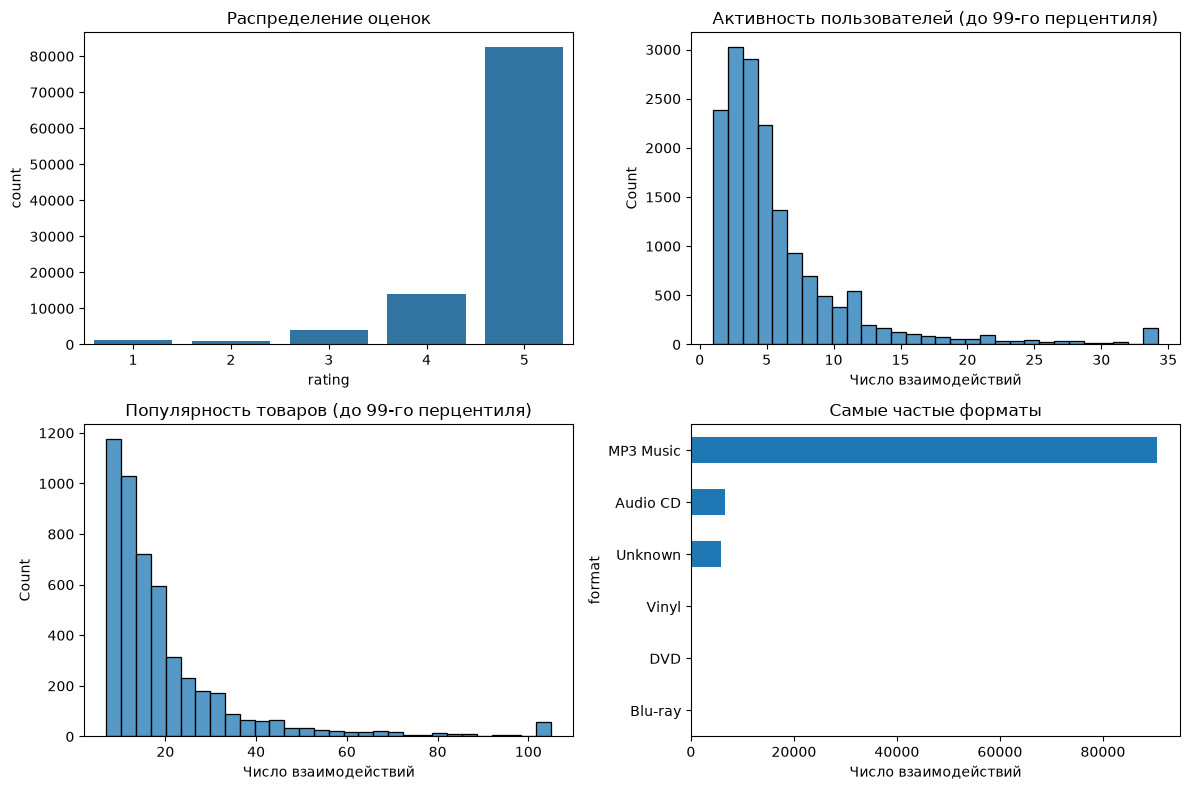

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=data, x="rating", ax=axes[0, 0])
axes[0, 0].set_title("Распределение оценок")

sns.histplot(user_freq.clip(upper=user_freq.quantile(0.99)), bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Активность пользователей (до 99-го перцентиля)")
axes[0, 1].set_xlabel("Число взаимодействий")

sns.histplot(item_freq.clip(upper=item_freq.quantile(0.99)), bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Популярность товаров (до 99-го перцентиля)")
axes[1, 0].set_xlabel("Число взаимодействий")

fmt_counts.head(6).sort_values().plot.barh(ax=axes[1, 1])
axes[1, 1].set_title("Самые частые форматы")
axes[1, 1].set_xlabel("Число взаимодействий")

plt.tight_layout()
plt.show()

Оценки сильно смещены в положительную сторону: около 80% имеют оценку 5. Медианный пользователь взаимодействовал с 4 товарами, а медианный товар получил около 15 взаимодействий. При этом встречаются намного более активные пользователи и популярные товары, то есть оба распределения имеют длинный хвост.

Основной формат - MP3 Music и Audio CD, а для около 5000 формат неизвестен.

Разреженность user-item матрицы больше 99%, поэтому далее будем хранить взаимодействия в разреженном формате.

## 3. Протокол оценки

Используем временное leave-last-two-out разбиение отдельно для каждого пользователя: последнее взаимодействие отложим в test, предпоследнее - в validation, остальные - в train. Так validation/test не влияют на выбор каталога. Validation используется только для выбора гиперпараметров, а после выбора настроек объединяется с train для финального обучения, test не участвует ни в одном выборе.

In [9]:
split_sizes = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "users": [train['user_id'].nunique(), val['user_id'].nunique(), test['user_id'].nunique()],
    "items": [train['item_id'].nunique(), val['item_id'].nunique(), test['item_id'].nunique()],
}, index=["train", "validation", "test"])
split_sizes

,rows,users,items
train,81942,15967,5000
validation,10870,10870,3605
test,10339,10339,3177


После ограничения каталога некоторые пользователи могут не иметь ни одного взаимодействия в train, хотя были в исходных данных. Их нельзя оценить на validation; аналогично на test исключаются пользователи без истории в train + validation и товары вне финального каталога. Правило применяется одинаково для всех методов. После выбора гиперпараметров модели переобучаются на train + validation.

In [10]:
val_ok = val["user_id"].isin(train["user_id"])
val_eval = val[val_ok].copy()

train_val = pd.concat([train, val], ignore_index=True)
test_ok = test["user_id"].isin(train_val["user_id"])
test_eval = test[test_ok].copy()

val_ties = (
    val_eval["timestamp"]
    == val_eval["user_id"].map(train.groupby("user_id")["timestamp"].max())
).sum()
test_ties = (
    test_eval["timestamp"]
    == test_eval["user_id"].map(train_val.groupby("user_id")["timestamp"].max())
).sum()

print(f"Исключено взаимодействий из validation: {(~val_ok).sum():,}")
print(f"Пользователей для оценки на validation: {len(val_eval):,}")
print(f"Исключено взаимодействий из test: {(~test_ok).sum():,}")
print(f"Пользователей для итоговой оценки: {len(test_eval):,}")

Исключено взаимодействий из validation: 308
Пользователей для оценки на validation: 10,562
Исключено взаимодействий из test: 104
Пользователей для итоговой оценки: 10,235


Для каждого пользователя кандидатами считаются все товары из выбранного обучающего каталога, кроме известных ему. На validation известными являются товары из train, а на test - товары из train + validation. Все модели формируют top-10 из одинакового набора кандидатов.

Основная метрика - NDCG@10. Дополнительная метрика - Recall@10: доля пользователей, для которых отложенный товар попал в top-10.

In [11]:
K = 10


def recall_at_k(recs, targets, k=K):
    recs = np.asarray(recs)[:, :k]
    targets = np.asarray(targets)
    hits = (recs == targets[:, None]).any(axis=1)
    return hits.mean()


def ndcg_at_k(recs, targets, k=K):
    recs = np.asarray(recs)[:, :k]
    targets = np.asarray(targets)
    matches = recs == targets[:, None]
    hits = matches.any(axis=1)
    ranks = matches.argmax(axis=1) + 1
    scores = np.where(hits, 1 / np.log2(ranks + 1), 0.0)
    return scores.mean()

Построим отображения ID в индексы и бинарную user-item матрицу: значение 1 означает наличие взаимодействия, 0 - отсутствие наблюдаемого взаимодействия.

In [12]:
def make_matrix(data, user_idx, item_idx):
    u = data["user_id"].map(user_idx)
    i = data["item_id"].map(item_idx)
    known = u.notna() & i.notna()

    return sp.csr_matrix(
        (
            np.ones(known.sum(), dtype=np.float32),
            (u[known].astype(int), i[known].astype(int)),
        ),
        shape=(len(user_idx), len(item_idx)),
    )

In [13]:
user_ids = np.sort(train["user_id"].unique())
item_ids = np.sort(train["item_id"].unique())
user_idx = {user_id: index for index, user_id in enumerate(user_ids)}
item_idx = {item_id: index for index, item_id in enumerate(item_ids)}

train_mat = make_matrix(train, user_idx, item_idx)
sparse_mb = (
    train_mat.data.nbytes
    + train_mat.indices.nbytes
    + train_mat.indptr.nbytes
) / 1024**2
dense_mb = np.prod(train_mat.shape) * 4 / 1024**2

print(f"Размер матрицы: {train_mat.shape}")

Размер матрицы: (15967, 5000)


## 4. Обучение и подбор гиперпараметров

### 4.1 Item-based Collaborative Filtering

Для товаров $i$ и $j$ используем cosine similarity по столбцам бинарной user-item матрицы:

$$sim(i,j)=\frac{|U_i \cap U_j|}{\sqrt{|U_i|}\sqrt{|U_j|}}.$$

Оценка кандидата $j$ для пользователя $u$ равна сумме его сходств с товарами из истории пользователя: $score(u,j)=\sum_{i \in I_u} sim(i,j)$. Уже известные товары исключаются.

In [14]:
from models.item_cf import ItemCF

val_users = val_eval["user_id"].map(user_idx).to_numpy()
val_targets = val_eval["item_id"].map(item_idx).to_numpy()

cf_results = []
for neighbors in [50, 100, 200, 400, 800]:
    model = ItemCF(neighbors=neighbors).fit(train_mat)
    recs = model.recommend(
        val_users, top_k=K
    )
    cf_results.append({
        "n_neighbors": neighbors,
        "Recall@10": recall_at_k(
            recs, val_targets
        ),
        "NDCG@10": ndcg_at_k(
            recs, val_targets
        ),
    })

cf_results = pd.DataFrame(cf_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_cf_k = int(cf_results.loc[0, "n_neighbors"])
print(f"Лучшие параметры: neighbors={best_cf_k}")
cf_results

Лучшие параметры: neighbors=800


,n_neighbors,Recall@10,NDCG@10
0,800,0.140882,0.092198
1,400,0.139178,0.091641
2,200,0.137095,0.090688
3,50,0.138137,0.090601
4,100,0.137095,0.090261


### 4.2 Implicit ALS

iALS раскладывает матрицу взаимодействий на матрицы пользовательских и товарных факторов. Предсказание задаётся скалярным произведением $score(u,i)=x_u^T y_i$. Для наблюдаемого взаимодействия $p_{ui}=1$, для ненаблюдаемого - $p_{ui}=0$, а уверенность равна $c_{ui}=1+\alpha r_{ui}$.

Оптимизируется функция:

$$\sum_{u,i} c_{ui}(p_{ui}-x_u^T y_i)^2 + \lambda(\sum_u ||x_u||^2 + \sum_i ||y_i||^2).$$

In [15]:
from models.ials import IALS

ials_results = []
for factors in [16, 32, 64]:
    for alpha in [10.0, 20.0, 40.0, 80.0]:
        for reg in [0.001, 0.01, 0.1, 1.0]:
            model = IALS(
                factors=factors,
                reg=reg,
                alpha=alpha,
                iters=5,
                seed=42,
            ).fit(train_mat)
            recs = model.recommend(
                val_users, top_k=K
            )
            ials_results.append({
                "n_factors": factors,
                "regularization": reg,
                "alpha": alpha,
                "Recall@10": recall_at_k(
                    recs, val_targets
                ),
                "NDCG@10": ndcg_at_k(
                    recs, val_targets
                ),
            })

ials_results = pd.DataFrame(ials_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_ials_f = int(ials_results.loc[0, "n_factors"])
best_ials_a = float(ials_results.loc[0, "alpha"])
best_ials_reg = float(ials_results.loc[0, "regularization"])

print(
    f"Лучшие параметры: factors={best_ials_f}, "
    f"alpha={best_ials_a}, reg={best_ials_reg}"
)
ials_results

Лучшие параметры: factors=64, alpha=40.0, reg=0.1


,n_factors,regularization,alpha,Recall@10,NDCG@10
0,64,0.100,40.0,0.135770,0.079744
1,64,1.000,20.0,0.136906,0.079540
2,64,1.000,40.0,0.135391,0.079523
3,64,0.010,20.0,0.137095,0.079353
4,64,0.001,40.0,0.135864,0.079310
5,64,0.001,20.0,0.136811,0.079260
6,64,0.010,40.0,0.135580,0.079239
7,64,0.100,20.0,0.136432,0.079178
8,64,0.100,80.0,0.130941,0.077799
9,64,0.010,80.0,0.132077,0.077796


### 4.3 EASE

Пусть $X$ - бинарная user-item матрица. Сначала вычисляется матрица Грама $G=X^TX+\lambda I$, затем $P=G^{-1}$. Веса связей между товарами задаются как

$$B_{ij}=-\frac{P_{ij}}{P_{jj}}, \qquad B_{jj}=0.$$

Оценки пользователя равны $XB$. Нулевая диагональ запрещает модели копировать товар самого в себя.

In [16]:
from models.ease import EASE

ease_results = []
for reg in [1.0, 10.0, 30.0, 100.0, 300.0, 1000.0]:
    model = EASE(reg=reg).fit(train_mat)
    recs = model.recommend(
        val_users, top_k=K
    )
    recall = recall_at_k(recs, val_targets)
    ndcg = ndcg_at_k(recs, val_targets)
    ease_results.append({
        "regularization": reg,
        "Recall@10": recall,
        "NDCG@10": ndcg,
    })
ease_results = pd.DataFrame(ease_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_ease_reg = float(ease_results.loc[0, "regularization"])

print(f"Лучшие параметры: reg={best_ease_reg}")
ease_results

Лучшие параметры: reg=100.0


,regularization,Recall@10,NDCG@10
0,100.0,0.163321,0.106187
1,30.0,0.159345,0.104668
2,300.0,0.163605,0.104616
3,1000.0,0.160197,0.102182
4,10.0,0.152149,0.101229
5,1.0,0.129521,0.087832


### 4.4 Factorization Machine с метапризнаками

FM моделирует линейные эффекты и попарные взаимодействия признаков:

$$\hat y(x)=w_0+\sum_j w_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$

Кроме ID пользователя и товара используем формат товара, активность и среднюю оценку пользователя, популярность и среднюю оценку товара.

In [17]:
from models.fm import FM

user_stats = train.groupby("user_id")["rating"].agg(["size", "mean"]).reindex(user_ids)
item_stats = train.groupby("item_id")["rating"].agg(["size", "mean"]).reindex(item_ids)

user_feat = np.column_stack([
    np.log1p(user_stats["size"].to_numpy()),
    user_stats["mean"].to_numpy(),
]).astype(np.float32)
item_feat = np.column_stack([
    np.log1p(item_stats["size"].to_numpy()),
    item_stats["mean"].to_numpy(),
]).astype(np.float32)

user_feat = (user_feat - user_feat.mean(axis=0)) / (user_feat.std(axis=0) + 1e-8)
item_feat = (item_feat - item_feat.mean(axis=0)) / (item_feat.std(axis=0) + 1e-8)

item_fmt = pd.crosstab(train["item_id"], train["format"]).idxmax(axis=1).reindex(item_ids)
formats = np.sort(item_fmt.unique())
fmt_idx = {value: index for index, value in enumerate(formats)}
item_fmt_idx = item_fmt.map(fmt_idx).to_numpy()



In [18]:
fm_grid = [
    {"n_factors": 8,  "learning_rate": 0.05, "regularization": 1e-5, "n_negatives": 1},
    {"n_factors": 16, "learning_rate": 0.05, "regularization": 1e-5, "n_negatives": 1},
    {"n_factors": 16, "learning_rate": 0.02, "regularization": 1e-5, "n_negatives": 1},
    {"n_factors": 16, "learning_rate": 0.05, "regularization": 1e-4, "n_negatives": 1},
    {"n_factors": 16, "learning_rate": 0.05, "regularization": 1e-5, "n_negatives": 2},
]
fm_results = []
for cfg in fm_grid:
    model = FM(
        factors=cfg["n_factors"],
        lr=cfg["learning_rate"],
        reg=cfg["regularization"],
        neg=cfg["n_negatives"],
    ).fit(train_mat, item_fmt_idx, user_feat, item_feat)
    recs = model.recommend(
        val_users, top_k=K
    )
    fm_results.append({
        **cfg,
        "Recall@10": recall_at_k(recs, val_targets),
        "NDCG@10": ndcg_at_k(recs, val_targets),
    })

fm_results = pd.DataFrame(fm_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_fm_f = int(fm_results.loc[0, "n_factors"])
best_fm_lr = float(fm_results.loc[0, "learning_rate"])
best_fm_reg = float(fm_results.loc[0, "regularization"])
best_fm_neg = int(fm_results.loc[0, "n_negatives"])
print(
    f"Лучшие параметры: factors={best_fm_f}, lr={best_fm_lr}, "
    f"reg={best_fm_reg}, negatives={best_fm_neg}"
)
fm_results

Лучшие параметры: factors=8, lr=0.05, reg=1e-05, negatives=1


,n_factors,learning_rate,regularization,n_negatives,Recall@10,NDCG@10
0,8,0.05,0.00001,1,0.033895,0.018408
1,16,0.02,0.00001,1,0.033895,0.018408
2,16,0.05,0.00001,1,0.033895,0.018408
3,16,0.05,0.00010,1,0.033895,0.018408
4,16,0.05,0.00001,2,0.033895,0.018341


### 4.5 iALS

В базовом iALS каждое взаимодействие имеет target $p_{ui}=1$. В нашей модели используем оценку и давность взаимодействия:

$$t_{ui}=\frac{r_{ui}}{5}\left[(1-\gamma)+\gamma\exp\left(-\frac{T_u-t_{ui}^{time}}{\tau}\right)\right],$$

где $r_{ui}$ - оценка, $T_u$ - время последнего взаимодействия пользователя в train, $\tau=730$ дней, а $\gamma$ управляет вкладом свежести. Таким образом, высокая свежая оценка получает target около 1, а низкая или старая - меньший target. Для неизвестных пар target остаётся нулевым. .

In [19]:
def make_target(gamma):
    target = (train["rating"] / 5.0) * (
        (1.0 - gamma) + gamma * fresh
    )
    return sp.csr_matrix(
        (
            target.astype(np.float32),
            (
                train["user_id"].map(user_idx),
                train["item_id"].map(item_idx),
            ),
        ),
        shape=train_mat.shape,
    )

In [20]:
from models.custom_ials import CustomIALS

user_last = train.groupby("user_id")["timestamp"].transform("max")
age = (user_last - train["timestamp"]) / (24 * 60 * 60)
fresh = np.exp(-age / 730.0)

custom_results = []
for gamma in [0.25, 0.5, 0.75]:
    custom_mat = make_target(gamma)
    model = CustomIALS(
        factors=best_ials_f,
        reg=best_ials_reg,
        alpha=best_ials_a,
        iters=5,
        seed=42,
    ).fit(custom_mat)
    recs = model.recommend(
        val_users, top_k=K
    )
    custom_results.append({
        "gamma": gamma,
        "tau_days": 730,
        "Recall@10": recall_at_k(recs, val_targets),
        "NDCG@10": ndcg_at_k(recs, val_targets),
    })

custom_results = pd.DataFrame(custom_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_gamma = float(custom_results.loc[0, "gamma"])
print(f"Лучшие параметры: gamma={best_gamma}")
custom_results

Лучшие параметры: gamma=0.75


,gamma,tau_days,Recall@10,NDCG@10
0,0.75,730,0.141166,0.083352
1,0.50,730,0.136906,0.082068
2,0.25,730,0.134634,0.080106


## 5. Итоговое сравнение на test

После выбора гиперпараметров объединяем train и validation и заново обучаем модели.

In [21]:
train_val = pd.concat([train, val], ignore_index=True)
fin_users = np.sort(train_val["user_id"].unique())
fin_items = np.sort(train_val["item_id"].unique())
fin_user_idx = {value: index for index, value in enumerate(fin_users)}
fin_item_idx = {value: index for index, value in enumerate(fin_items)}
fin_mat = make_matrix(
    train_val, fin_user_idx, fin_item_idx
)

test_users = test_eval["user_id"].map(fin_user_idx).to_numpy()
test_targets = test_eval["item_id"].map(fin_item_idx).to_numpy()
test_results = []

def test_model(name, params, model):
    recs = model.recommend(test_users, top_k=K)
    test_results.append({
        "model": name,
        "hyperparameters": params,
        "Recall@10": recall_at_k(recs, test_targets),
        "NDCG@10": ndcg_at_k(recs, test_targets),
    })

print("Пользователей на test:", len(test_users))

Пользователей на test: 10235


In [22]:
model = ItemCF(neighbors=best_cf_k).fit(fin_mat)
test_model("ItemCF", f"neighbors={best_cf_k}", model)

In [23]:
model = IALS(
    factors=best_ials_f,
    reg=best_ials_reg,
    alpha=best_ials_a, iters=5, seed=42,
).fit(fin_mat)
test_model(
    "iALS",
    f"factors={best_ials_f}, reg={best_ials_reg}, alpha={best_ials_a}",
    model,
)

In [24]:
model = EASE(reg=best_ease_reg).fit(fin_mat)
test_model("EASE", f"reg={best_ease_reg}", model)

In [25]:
fin_user_stats = train_val.groupby("user_id")["rating"].agg(["size", "mean"]).reindex(fin_users)
fin_item_stats = train_val.groupby("item_id")["rating"].agg(["size", "mean"]).reindex(fin_items)
fin_user_feat = np.column_stack([
    np.log1p(fin_user_stats["size"].to_numpy()),
    fin_user_stats["mean"].to_numpy(),
]).astype(np.float32)
fin_item_feat = np.column_stack([
    np.log1p(fin_item_stats["size"].to_numpy()),
    fin_item_stats["mean"].to_numpy(),
]).astype(np.float32)
fin_user_feat = (fin_user_feat - fin_user_feat.mean(axis=0)) / (fin_user_feat.std(axis=0) + 1e-8)
fin_item_feat = (fin_item_feat - fin_item_feat.mean(axis=0)) / (fin_item_feat.std(axis=0) + 1e-8)

fin_item_fmt = pd.crosstab(train_val["item_id"], train_val["format"]).idxmax(axis=1).reindex(fin_items)
fin_formats = np.sort(fin_item_fmt.unique())
fin_fmt_idx = {value: index for index, value in enumerate(fin_formats)}
fin_fmt_codes = fin_item_fmt.map(fin_fmt_idx).to_numpy()

model = FM(
    factors=best_fm_f,
    lr=best_fm_lr,
    reg=best_fm_reg,
    neg=best_fm_neg,
).fit(fin_mat, fin_fmt_codes, fin_user_feat, fin_item_feat)
test_model(
    "FM",
    f"factors={best_fm_f}, lr={best_fm_lr}, reg={best_fm_reg}, neg={best_fm_neg}",
    model,
)

In [26]:
fin_user_last = train_val.groupby("user_id")["timestamp"].transform("max")
fin_age = (fin_user_last - train_val["timestamp"]) / (24 * 60 * 60)
fin_fresh = np.exp(-fin_age / 730.0)
fin_target = (train_val["rating"] / 5.0) * (
    (1.0 - best_gamma) + best_gamma * fin_fresh
)
fin_custom_mat = sp.csr_matrix(
    (
        fin_target.astype(np.float32),
        (
            train_val["user_id"].map(fin_user_idx),
            train_val["item_id"].map(fin_item_idx),
        ),
    ),
    shape=fin_mat.shape,
)

model = CustomIALS(
    factors=best_ials_f,
    reg=best_ials_reg,
    alpha=best_ials_a, iters=5, seed=42,
).fit(fin_custom_mat)
test_model(
    "Custom iALS",
    f"factors={best_ials_f}, reg={best_ials_reg}, alpha={best_ials_a}, gamma={best_gamma}",
    model,
)

In [27]:
test_results = pd.DataFrame(test_results).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
test_results

,model,hyperparameters,Recall@10,NDCG@10
0,EASE,reg=100.0,0.160332,0.107447
1,ItemCF,neighbors=800,0.136688,0.093641
2,Custom iALS,"factors=64, reg=0.1, alpha=40.0, gamma=0.75",0.137469,0.084784
3,iALS,"factors=64, reg=0.1, alpha=40.0",0.135125,0.081639
4,FM,"factors=8, lr=0.05, reg=1e-05, neg=1",0.035271,0.018971


## 6. Выводы

Лучшей моделью оказалась EASE: Recall@10 = 0.1603, NDCG@10 = 0.1074. Второе место по NDCG@10 заняла ItemCF. В целом модели, которые используют сходство товаров, отработали лучше остальных.

Custom iALS немного улучшила обычную iALS за счёт оценки и свежести взаимодействия: NDCG@10 вырос с 0.0816 до 0.0848. Улучшение небольшое, поэтому нельзя уверенно сказать, что оно не случайное. FM показала худший результат, скорее всего потому, что признаки товаров слишком простые.

У эксперимента есть ограничения. Часть пользователей после фильтрации становится cold-start. При одинаковом timestamp порядок событий определяется по `item_id`, и общей временной границы для всех пользователей нет.